In [1]:
%load_ext cuml.accel
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.cluster import DBSCAN
from sklearn.metrics import confusion_matrix
import warnings
warnings.filterwarnings('ignore')

[2025-07-04 08:54:18.470] [CUML] [info] cuML: Installed accelerator for sklearn.
[2025-07-04 08:54:50.937] [CUML] [info] cuML: Installed accelerator for umap.
[2025-07-04 08:54:51.045] [CUML] [info] cuML: Installed accelerator for hdbscan.
[2025-07-04 08:54:51.045] [CUML] [info] cuML: Successfully initialized accelerator.


In [3]:
def load_and_preprocess_data(file_path):
    df = pd.read_csv(file_path)
    df = df.drop(['zipcodeOri', 'zipMerchant'], axis=1)
    for col in ['customer', 'age', 'gender', 'merchant', 'category']:
        df[col] = df[col].str.strip("'")
    df['category'] = df['category'].str.replace('es_', '')
    df = df[df['gender'] != 'U']
    df.loc[df['age'] == 'U', 'age'] = '7'
    bins = [0, 500, 1000, 1500, 2000, 2500, 3000, float('inf')]
    labels = ['0-500', '500-1000', '1000-1500', '1500-2000', '2000-2500', '2500-3000', '>3000']
    df['amount_bin'] = pd.cut(df['amount'], bins=bins, labels=labels, include_lowest=True)

    return df

In [4]:
def engineer_features(df):
    cust_stats = df.groupby('customer').size().reset_index(name='cust_trans_count')
    cust_stats['cust_id'] = range(1, len(cust_stats) + 1)

    merch_stats = df.groupby('merchant').size().reset_index(name='merch_trans_count')
    merch_stats['merch_id'] = range(1, len(merch_stats) + 1)

    cat_stats = df.groupby('category').size().reset_index(name='cat_trans_count')
    cat_stats['cat_id'] = range(1, len(cat_stats) + 1)

    amt_bin_stats = df.groupby('amount_bin').size().reset_index(name='amt_bin_trans_count')
    amt_bin_stats['amt_bin_id'] = range(1, len(amt_bin_stats) + 1)

    df = (df.merge(cust_stats, on='customer')
            .merge(merch_stats, on='merchant')
            .merge(cat_stats, on='category')
            .merge(amt_bin_stats, on='amount_bin'))

    df['age'] = df['age'].astype(float)
    df['gender'] = df['gender'].map({'M': 1, 'F': 2, 'E': 3})

    total_trans = len(df)
    for col in ['merch_trans_count', 'cat_trans_count', 'amt_bin_trans_count']:
        df[col] = (df[col] / total_trans * 100).round(5)

    df['fraud'] = df['fraud'].map({1: 'F', 0: 'NF'})

    return df.drop(['step', 'customer', 'merchant', 'amount_bin'], axis=1)


In [5]:
def perform_kmeans_clustering(data):
    features = ['amount', 'gender', 'age', 'cat_id', 'merch_trans_count',
                'cust_trans_count', 'merch_id', 'cat_trans_count', 'cust_id',
                'amt_bin_id', 'amt_bin_trans_count']

    scaler = StandardScaler()
    scaled_data = scaler.fit_transform(data[features])

    kmeans = KMeans(n_clusters=3, random_state=123, n_init=25)
    clusters = kmeans.fit_predict(scaled_data)

    pca = PCA(n_components=3)
    pca_result = pca.fit_transform(scaled_data)

    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection='3d')
    scatter = ax.scatter(pca_result[:, 0], pca_result[:, 1], pca_result[:, 2],
                        c=clusters, cmap='viridis', alpha=0.6)
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
    ax.set_zlabel('PC3')
    ax.set_title(f'KMeans Clustering (3 Clusters)\nExplained Variance: {pca.explained_variance_ratio_.sum():.2%}')
    plt.colorbar(scatter, label='Cluster')
    plt.tight_layout()
    plt.show()

    data['cluster'] = clusters
    print("\nCluster Distribution:")
    print(data.groupby(['cluster', 'fraud']).size().unstack(fill_value=0))

    distances = np.sqrt(((scaled_data - kmeans.cluster_centers_[clusters])**2).sum(axis=1))
    threshold = np.percentile(distances, 95)
    data['suspect'] = np.where(distances > threshold, 'F', 'NF')

    cm = confusion_matrix(data['fraud'], data['suspect'], labels=['F', 'NF'])
    print("\nKMeans Confusion Matrix:")
    print(cm)

    for cluster in range(3):
        print(f"\nCluster {cluster} Analysis:")
        cluster_data = data[data['cluster'] == cluster]
        print(f"Size: {len(cluster_data)}")
        print("Fraud Distribution:")
        print(cluster_data['fraud'].value_counts())

        non_fraud = cluster_data[cluster_data['fraud'] == 'NF']
        if not non_fraud.empty:
            print("\nNon-Fraud Characteristics:")
            print(f"Mean Amount: ${non_fraud['amount'].mean():.2f}")
            print("Top Categories:")
            print(non_fraud['category'].value_counts().head())

        fraud = cluster_data[cluster_data['fraud'] == 'F']
        if not fraud.empty:
            print("\nFraud Characteristics:")
            print(f"Mean Amount: ${fraud['amount'].mean():.2f}")
            print("Top Categories:")
            print(fraud['category'].value_counts().head())

    return data


In [9]:
def perform_dbscan_clustering(data):
    features = ['amount', 'gender', 'age', 'cat_id', 'merch_trans_count',
                'cust_trans_count', 'merch_id', 'cat_trans_count', 'cust_id',
                'amt_bin_id', 'amt_bin_trans_count']

    scaler = StandardScaler()
    scaled_data = scaler.fit_transform(data[features])

    dbscan = DBSCAN(eps=0.4, min_samples=7)
    clusters = dbscan.fit_predict(scaled_data)

    pca = PCA(n_components=3)
    pca_result = pca.fit_transform(scaled_data)

    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection='3d')
    scatter = ax.scatter(pca_result[:, 0], pca_result[:, 1], pca_result[:, 2],
                        c=clusters, cmap='viridis', alpha=0.6)
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
    ax.set_zlabel('PC3')
    ax.set_title(f'DBSCAN Clustering\nExplained Variance: {pca.explained_variance_ratio_.sum():.2%}')
    plt.colorbar(scatter, label='Cluster')
    plt.tight_layout()
    plt.show()

    data['dbscan_cluster'] = clusters
    data['suspect'] = np.where(data['dbscan_cluster'] == 0, 'F', 'NF')

    cm = confusion_matrix(data['fraud'], data['suspect'], labels=['F', 'NF'])
    print("\nDBSCAN Confusion Matrix:")
    print(cm)

    print("\nCluster 0 (Main Suspect Cluster) Analysis:")
    cluster_0 = data[data['dbscan_cluster'] == 0]
    print(f"Size: {len(cluster_0)}")
    print("Fraud Distribution:")
    print(cluster_0['fraud'].value_counts())

    non_fraud = cluster_0[cluster_0['fraud'] == 'NF']
    if not non_fraud.empty:
        print("\nNon-Fraud Characteristics:")
        print(f"Mean Amount: ${non_fraud['amount'].mean():.2f}")
        print("Top Categories:")
        print(non_fraud['category'].value_counts().head())

    fraud = cluster_0[cluster_0['fraud'] == 'F']
    if not fraud.empty:
        print("\nFraud Characteristics:")
        print(f"Mean Amount: ${fraud['amount'].mean():.2f}")
        print("Top Categories:")
        print(fraud['category'].value_counts().head())

    return data


In [7]:
import kagglehub

path = kagglehub.dataset_download("ealaxi/banksim1")
print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/banksim1


KMeans Clustering Results:


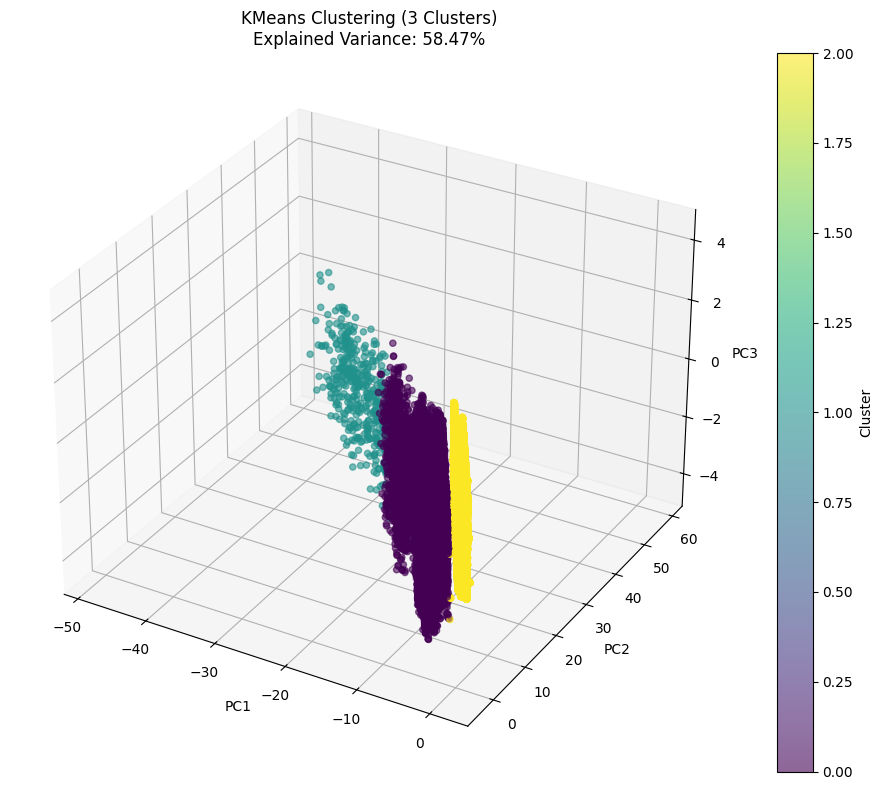


Cluster Distribution:
fraud       F      NF
cluster              
0        6779   82243
1         413      11
2           8  504674

KMeans Confusion Matrix:
[[  4709   2491]
 [ 24998 561930]]

Cluster 0 Analysis:
Size: 89022
Fraud Distribution:
fraud
NF    82243
F      6779
Name: count, dtype: int64

Non-Fraud Characteristics:
Mean Amount: $61.61
Top Categories:
category
food                  26228
health                14416
wellnessandbeauty     14363
fashion                6332
barsandrestaurants     6250
Name: count, dtype: int64

Fraud Characteristics:
Mean Amount: $353.96
Top Categories:
category
sportsandtoys        1982
health               1690
wellnessandbeauty     710
hotelservices         548
leisure               474
Name: count, dtype: int64

Cluster 1 Analysis:
Size: 424
Fraud Distribution:
fraud
F     413
NF     11
Name: count, dtype: int64

Non-Fraud Characteristics:
Mean Amount: $1767.47
Top Categories:
category
travel    11
Name: count, dtype: int64

Fraud Characte

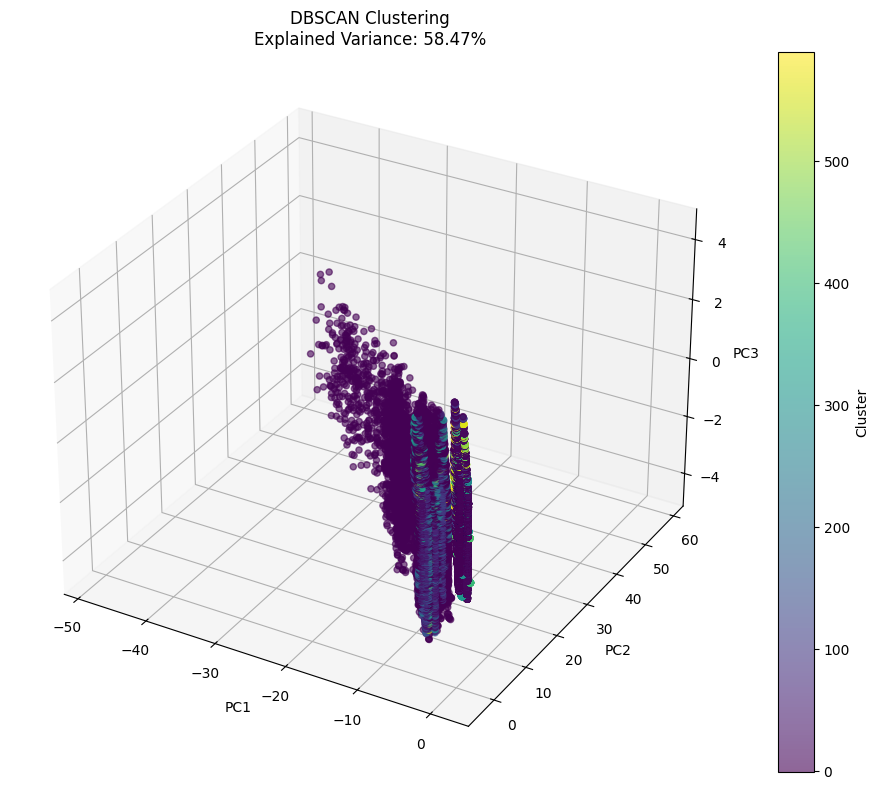


DBSCAN Confusion Matrix:
[[     0   7200]
 [ 14760 572168]]

Cluster 0 (Main Suspect Cluster) Analysis:
Size: 14760
Fraud Distribution:
fraud
NF    14760
Name: count, dtype: int64

Non-Fraud Characteristics:
Mean Amount: $27.06
Top Categories:
category
transportation    14760
Name: count, dtype: int64


In [8]:

data = load_and_preprocess_data(path+"/bs140513_032310.csv")
data = engineer_features(data)

print("KMeans Clustering Results:")
kmeans_data = perform_kmeans_clustering(data.copy())

print("\nDBSCAN Clustering Results:")
dbscan_data = perform_dbscan_clustering(data.copy())

[2025-07-04 09:07:50.083] [CUML] [warning] Batch size limited by the chosen integer type (4 bytes). 4243 -> 3614. Using the larger integer type might result in better performance


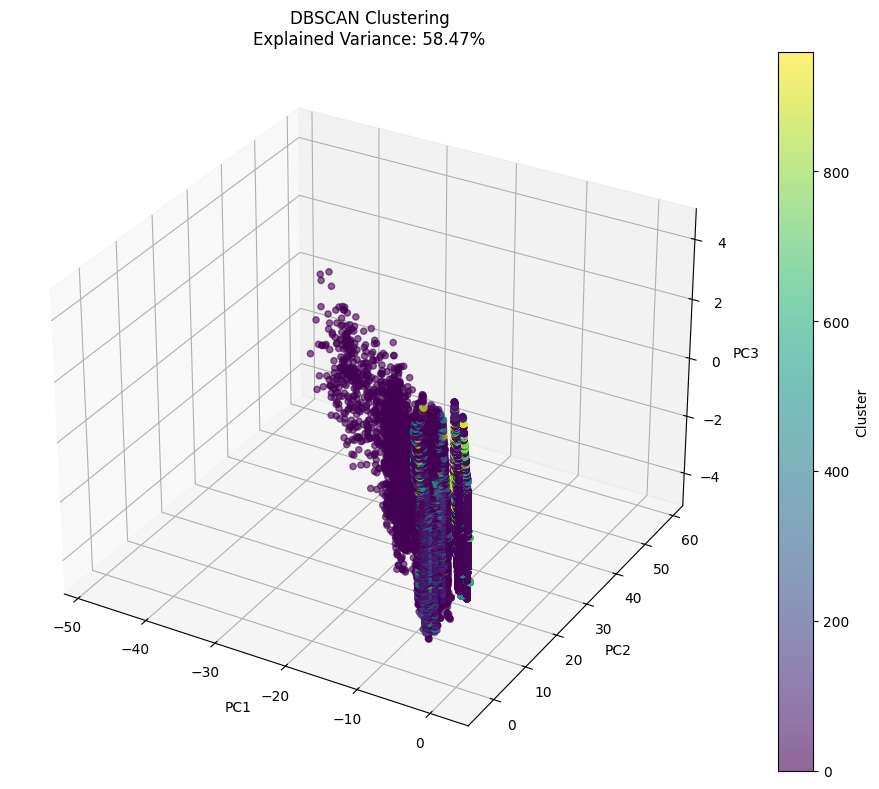


DBSCAN Confusion Matrix:
[[     0   7200]
 [ 14563 572365]]

Cluster 0 (Main Suspect Cluster) Analysis:
Size: 14563
Fraud Distribution:
fraud
NF    14563
Name: count, dtype: int64

Non-Fraud Characteristics:
Mean Amount: $27.05
Top Categories:
category
transportation    14563
Name: count, dtype: int64


In [10]:
dbscan_data = perform_dbscan_clustering(data.copy())